## 1. The task

Every graph in UPFD Gossipcop is the retweet cascade of one news story. The root is the news item, and every other node is a Twitter user who shared it, joined to the account they got it from. We predict one label $y\in\{0,1\}$ for the whole cascade, fake or real. This is graph classification.

The model is the **enhanced classic GNN** of Lecture 17 and Luo, Shi and Wu (ICML 2025), *Can Classic GNNs Be Strong Baselines for Graph-level Tasks?*: a GCN layer wrapped in normalization, dropout, residual connections, a feed-forward network and positional encodings. We call it **GCN⁺**. The readout, the step that turns the node embeddings into one graph vector, is tuned like any other hyperparameter: flat sum, mean and max, a **news-aware** readout that treats the root differently from the users, and the hierarchical poolers **SAGPool**, **DiffPool** and **MinCutPool**.

The notebook first tunes GCN⁺ on the validation split (Milestone 2) and then runs the Milestone 3 analyses on the tuned model: ablations, readouts, depth, dropout, t-SNE, efficiency, robustness, errors by cascade shape and explainability.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`; the ablations use the first five, `abl_seeds`, and the depth and dropout sweeps the first three, `sweep_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 30, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds, sweep_seeds = final_seeds[:5], final_seeds[:3]

## 3. Load the three official splits

PyG ships UPFD with a fixed split: 20% train, 10% validation and 70% test. We keep it, so all three models are scored on exactly the same graphs. We use the `'content'` node features: for the news node a 300-dimensional spaCy embedding of the article, and for a user a 300-dimensional spaCy embedding of their recent tweets plus 10 profile features, 310 numbers in all.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the output. PyG warns on every max-pooling call that an optional package would make it faster; we silence that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import UPFD
warnings.filterwarnings('ignore', message='.*can be accelerated via')

raw = {s: UPFD('/tmp/upfd', 'gossipcop', 'content', s) for s in ['train', 'val', 'test']}
device = 'cuda' if torch.cuda.is_available() else 'cpu'
for s in raw:
    print(s, "  graphs =", len(raw[s]))
print("node features =", raw['train'].num_features, "   device =", device)

train   graphs = 1092
val   graphs = 546
test   graphs = 3826
node features = 310    device = cuda


## 4. Which node is the news item?

A cascade grows outwards from the news node, and PyG stores each edge once, as parent $\rightarrow$ child. We check three things on every graph: is it directed, is it a tree ($|E|=|V|-1$), and is node $0$ the root, the one node with no incoming edge. If node $0$ is always the root, the news node of every graph in a mini-batch is simply that graph's first node, which the news-aware readout relies on.

In [4]:
from torch_geometric.utils import degree
allg = [g for s in raw for g in raw[s]]
indeg0 = lambda g: (degree(g.edge_index[1], g.num_nodes) == 0).nonzero().flatten().tolist()
print("directed graphs:  ", sum(not g.is_undirected() for g in allg), "of", len(allg))
print("trees (|E|=|V|-1):", sum(g.num_edges == g.num_nodes - 1 for g in allg))
print("node 0 is the only root:", sum(indeg0(g) == [0] for g in allg))
sizes = torch.tensor([g.num_nodes for g in allg]).float()
print("nodes per graph: mean =", round(sizes.mean().item(), 1), "  median =", sizes.median().item(), "  max =", int(sizes.max()))

directed graphs:   5464 of 5464
trees (|E|=|V|-1): 5464
node 0 is the only root: 5464
nodes per graph: mean = 57.5   median = 49.0   max = 199


## 5. Make the cascades undirected and add positional encodings

With parent $\rightarrow$ child edges only, messages flow away from the news node and the news node never hears from its users. `ToUndirected()` adds the reverse of every edge.

The sixth trick of Luo et al. is a **positional encoding** $\mathbf{p}_v$ that tells each node where it sits. We use random-walk encodings,

$\mathbf{p}_v=\big[(\mathbf{D}^{-1}\mathbf{A})^{k}\big]_{vv},\quad k=1,\dots,16,$

the probability that a random walk from $v$ is back at $v$ after $k$ steps. On a directed tree a walk can never return, so every encoding would be zero; after `ToUndirected()` it can. A tree has no odd cycles, so the odd steps are always zero; the even steps tell a hub (low return probability, many exits) from a leaf (it must come straight back). We keep the 8 even steps.

In [5]:
from torch_geometric.transforms import ToUndirected, AddRandomWalkPE
und, rw = ToUndirected(), AddRandomWalkPE(walk_length=16, attr_name='pe')
def prep(g):
    g = rw(und(g))
    g.pe = g.pe[:, 1::2]
    return g
train_set, val_set, test_set = [[prep(g) for g in raw[s]] for s in raw]
print("all undirected:", all(g.is_undirected() for g in train_set + val_set + test_set))
g = train_set[0]
print(g)
print("encoding of the news node:", g.pe[0].numpy().round(3))
print("encoding of a leaf user:  ", g.pe[-1].numpy().round(3))

all undirected: True
Data(x=[76, 310], edge_index=[2, 150], y=[1], pe=[76, 8])
encoding of the news node: [0.986 0.978 0.972 0.969 0.966 0.965 0.963 0.962]
encoding of a leaf user:   [0.5   0.375 0.282 0.213 0.162 0.124 0.095 0.074]


## 6. Class balance and reference points

Every number later in the notebook needs something to be compared with. We use three references on the test split:

- always predicting the larger class;
- a logistic regression on $\log|V|$, the size of the cascade alone;
- a logistic regression on the 310 features of the news node alone, i.e. the article without any users.

If a GNN cannot beat the third one, the cascade adds nothing to the article.

In [6]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train, y_val, y_test = [np.array([g.y.item() for g in d]) for d in [train_set, val_set, test_set]]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  real (0) =", (yy == 0).sum(), "  fake (1) =", (yy == 1).sum())
logn = lambda d: np.log([[g.num_nodes] for g in d])
news = lambda d: np.stack([g.x[0].numpy() for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
news_acc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(news(train_set), y_train).score(news(test_set), y_test)
majority = max(np.mean(y_test == 0), np.mean(y_test == 1))
print("\ntest accuracy, always the larger class:", round(majority, 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))
print("test accuracy from the news node alone:", round(news_acc, 4))

train   graphs = 1092   real (0) = 557   fake (1) = 535
val   graphs = 546   real (0) = 265   fake (1) = 281
test   graphs = 3826   real (0) = 1910   fake (1) = 1916

test accuracy, always the larger class: 0.5008
test accuracy from log|V| alone:       0.7522
test accuracy from the news node alone: 0.9373


## 7. The message-passing layer: GCN

The core of every block is a GCN layer (Kipf and Welling, 2017):

$\mathbf{h}_v'=\sum_{u\in\mathcal{N}(v)\cup\{v\}}\frac{1}{\sqrt{\hat d_u\hat d_v}}\,\mathbf{h}_u\mathbf{W},$

a degree-weighted average over the node and its neighbours, where $\hat d$ counts the self-loop. In a cascade the news node can have hundreds of neighbours, so the $1/\sqrt{\hat d_u\hat d_v}$ factor shrinks every message that passes through it. Luo et al. also add $\mathbf{e}_{uv}\mathbf{W}_e$ for edge features; UPFD has none, so the layer is the plain GCN. Inside a block the layer keeps the width `hidden` of its input.

In [7]:
import torch.nn.functional as F
from torch.nn import Linear, BatchNorm1d, Identity, Sequential, ReLU, Dropout, ModuleList
from torch_geometric.utils import to_dense_batch, to_dense_adj
from torch_geometric.nn import GCNConv
make_conv = lambda h: GCNConv(h, h)
conv = make_conv(16)
print("one GCN layer:", (g.num_nodes, 16), "->", tuple(conv(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one GCN layer: (76, 16) -> (76, 16)


## 8. One GCN⁺ block

Luo et al. wrap every message-passing layer in the same block (Lecture 17, *The Enhanced Classic GNN*):

1. **Message passing** with the GCN layer above.
2. **Normalization**: batch norm keeps every feature on the same scale from batch to batch.
3. **Activation and dropout**: ReLU, then each value is zeroed with probability $p$ and the rest scaled by $1/(1-p)$.
4. **Residual connection**: $\mathbf{h}_v^{l}=\mathrm{Dropout}(\sigma(\mathrm{BN}(\cdots)))+\mathbf{h}_v^{l-1}$.
5. **Feed-forward network**: $\mathrm{FFN}(\mathbf{h})=\mathrm{BN}\big(\sigma(\mathbf{h}\mathbf{W}_1)\mathbf{W}_2+\mathbf{h}\big)$, applied to every node.

Each trick has a switch (`norm`, `res`, `ffn`, and `dropout=0`) so that we can remove it later. The first trick of the paper, **edge features**, cannot be used: UPFD stores nothing on its edges.

In [8]:
BLOCK_EXTRA = []

class Block(torch.nn.Module):
    def __init__(self, h, dropout, norm, res, ffn):
        super().__init__()
        self.conv = make_conv(h)
        self.bn = BatchNorm1d(h) if norm else Identity()
        self.ffn = Sequential(Linear(h, 2 * h), ReLU(), Dropout(dropout), Linear(2 * h, h)) if ffn else None
        self.bn2 = BatchNorm1d(h) if (ffn and norm) else Identity()
        self.dropout, self.res = dropout, res

    def forward(self, x, edge_index, batch=None):
        h = F.dropout(self.bn(self.conv(x, edge_index)).relu(), self.dropout, self.training)
        if self.res:
            h = h + x
        if self.ffn is not None:
            h = self.bn2(h + self.ffn(h))
        return h

blk = Block(16, 0.2, True, True, True)
print("one block:", (g.num_nodes, 16), "->", tuple(blk(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one block: (76, 16) -> (76, 16)


## 9. From node embeddings to one graph vector

The readout must turn a cascade of any size into one vector of fixed size, and must not depend on the order in which the nodes are stored. A cascade has **two kinds of node**: one news item and many users. We compare seven readouts:

- **sum**, **mean** and **max**: flat, one-shot pooling over all nodes; the news node is just one node among many.
- **news-aware**: $\mathbf{h}_G=[\,\mathbf{h}_{\text{news}}\,\|\,\mathrm{mean}(\text{users})\,\|\,\mathrm{max}(\text{users})\,]$. The news node gets its own slot and the users are pooled separately, so the article cannot be drowned by hundreds of users. This is our version of the UPFD paper's root shortcut, applied to the learned embedding.
- **SAGPool** (Lee et al., ICML 2019): a graph convolution gives every node a score $z_v=\tanh(\mathrm{GCN}(\mathbf{H}))_v$; the top half of the nodes is kept, their embeddings are multiplied by their scores, and the kept nodes are read out with mean $\|$ max. It learns *which* nodes matter. We rank the nodes by the raw score before the $\tanh$ (the order is the same, since $\tanh$ is increasing) because PyG's `SAGPooling` ranks after it: once $\tanh$ saturates, many nodes tie at exactly $1.0$, the tie is broken by node index, and the readout stops being permutation invariant.
- **DiffPool** (Ying et al., NeurIPS 2018): a soft assignment $\mathbf{S}=\mathrm{softmax}(\mathbf{H}\mathbf{W}_S)\in\mathbb{R}^{n\times k}$ maps the nodes onto $k$ clusters, giving $\mathbf{H}'=\mathbf{S}^\top\mathbf{H}$ and $\mathbf{A}'=\mathbf{S}^\top\mathbf{A}\mathbf{S}$. A link loss and an entropy loss are added to training.
- **MinCutPool** (Bianchi et al., ICML 2020): the same soft assignment, but trained with a normalized-cut loss and an orthogonality loss that push the clusters to be balanced and well separated. Its losses are better behaved than DiffPool's.

For DiffPool and MinCutPool we use $k=15$ clusters, about a quarter of the average cascade, run one dense graph convolution on the pooled graph and average the clusters. Both need the graphs as padded dense tensors; a mini-batch is padded only to its largest cascade.

Each node enters with $\mathbf{h}_v^{(0)}=[\mathbf{W}_x\mathbf{x}_v\,\|\,\mathbf{W}_p\mathrm{BN}(\mathbf{p}_v)]$: the 8 encoding values are normalised and mapped to 16 of the `hidden` dimensions, or to none if `pe=False`.

In [9]:
from torch_geometric.nn import MLP, GCNConv, DenseGCNConv, DenseGraphConv, dense_diff_pool, dense_mincut_pool
from torch_geometric.nn.pool.select.topk import topk
from torch_geometric.nn import global_mean_pool, global_max_pool, global_add_pool
from torch_geometric.utils import to_dense_batch, to_dense_adj

flat = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)
F_IN, PE_DIM = 310, 8

def news_index(batch):
    n = torch.bincount(batch)
    return n.cumsum(0) - n

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=3, dropout=0.2, pool='mean',
                 norm=True, res=True, ffn=True, pe=True, clusters=15, **kw):
        super().__init__()
        self.use_pe, self.pool = pe, pool
        self.node = Linear(F_IN, hidden - 16 if pe else hidden)
        self.pe_norm, self.pe_lin = BatchNorm1d(PE_DIM), Linear(PE_DIM, 16)
        extra = {k: kw[k] for k in BLOCK_EXTRA if k in kw}
        self.blocks = ModuleList([Block(hidden, dropout, norm, res, ffn, **extra) for _ in range(layers)])
        if pool == 'sag':
            self.score = GCNConv(hidden, 1)
        if pool in ['diff', 'mincut']:
            self.assign = Linear(hidden, clusters)
            self.dconv = DenseGCNConv(hidden, hidden) if pool == 'diff' else DenseGraphConv(hidden, hidden)
        out = dict(sag=2 * hidden, news=3 * hidden).get(pool, hidden)
        self.head = MLP([out, hidden, 2], dropout=dropout, norm=None)
        self.aux = torch.zeros(())

    def nodes(self, x, edge_index, pe, batch):
        h = self.node(x)
        if self.use_pe:
            h = torch.cat([h, self.pe_lin(self.pe_norm(pe))], dim=1)
        for b in self.blocks:
            h = b(h, edge_index, batch)
        return h

    def embed(self, x, edge_index, pe, batch=None):
        if batch is None:
            batch = edge_index.new_zeros(x.size(0))
        h = self.nodes(x, edge_index, pe, batch)
        self.aux = h.new_zeros(())
        if self.pool in flat:
            return flat[self.pool](h, batch)
        if self.pool == 'news':
            root = news_index(batch)
            user = torch.ones(h.size(0), dtype=torch.bool, device=h.device); user[root] = False
            hu, bu = h[user], batch[user]
            G = root.numel()
            return torch.cat([h[root], global_mean_pool(hu, bu, G), global_max_pool(hu, bu, G)], dim=1)
        if self.pool == 'sag':
            z = self.score(h, edge_index).view(-1)
            keep = topk(z, 0.5, batch)
            hs, bs, G = h[keep] * torch.tanh(z[keep]).view(-1, 1), batch[keep], int(batch.max()) + 1
            return torch.cat([global_mean_pool(hs, bs, G), global_max_pool(hs, bs, G)], dim=1)
        xd, mask = to_dense_batch(h, batch)
        adj = to_dense_adj(edge_index, batch, max_num_nodes=xd.size(1))
        s, _ = to_dense_batch(self.assign(h), batch)
        if self.pool == 'diff':
            xp, ap, l1, l2 = dense_diff_pool(xd, adj, s, mask)
        else:
            xp, ap, l1, l2 = dense_mincut_pool(xd, adj, s, mask)
        self.aux = l1 + l2
        return self.dconv(xp, ap).relu().mean(1)

    def forward(self, x, edge_index, pe, batch=None):
        return self.head(self.embed(x, edge_index, pe, batch))

for p in ['mean', 'news', 'sag', 'diff', 'mincut']:
    out = Net(pool=p)(g.x, g.edge_index, g.pe)
    print(f"{p:7s} readout -> logits {tuple(out.shape)}")

mean    readout -> logits (1, 2)
news    readout -> logits (1, 2)
sag     readout -> logits (1, 2)
diff    readout -> logits (1, 2)
mincut  readout -> logits (1, 2)


## 10. Train with early stopping on validation accuracy

We minimise cross-entropy, plus the auxiliary losses of DiffPool or MinCutPool when one of them is the readout, with Adam on mini-batches of training graphs. Gradients are clipped to norm 5: without batch norm a sum over hundreds of retweets at the news node can blow up, and a run whose loss becomes NaN stops and keeps its best weights so far. After every epoch we measure validation accuracy, keep the best weights, and stop once it has not improved for `patience` epochs. The test split is never used here.

`predict` returns $P(\text{fake}\mid G)$ for every graph, and `scores` turns those probabilities into accuracy, macro-F1 and ROC-AUC. Accuracy is the primary metric, as in the UPFD paper; the classes are nearly balanced, so it is not misleading.

In [10]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=256):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

val_b, test_b = batches(val_set), batches(test_set)

@torch.no_grad()
def predict(model, bs):
    model.eval()
    p = torch.cat([model(b.x, b.edge_index, b.pe, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()
    return np.nan_to_num(p, nan=0.5)

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait, state = -1, 0, None
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y) + model.aux
            if not torch.isfinite(loss):
                break
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        if not torch.isfinite(loss):
            break
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

## 11. Reference: the plain GCN

Before adding anything we train a textbook starting point with every trick switched off (no normalization, residuals, FFN or positional encoding): two GCN layers of width 64, mean readout, and the dropout ($0.5$), learning rate ($0.01$) and weight decay ($5\cdot10^{-4}$) of Kipf and Welling's original GCN. All three UPFD notebooks use the same reference settings, so their plain baselines are comparable. It runs on the ten final seeds.

In [11]:
plain = dict(hidden=64, layers=2, dropout=0.5, pool='mean', norm=False, res=False, ffn=False, pe=False, lr=0.01, wd=5e-4)
base = pd.DataFrame([scores(y_test, predict(fit(plain, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.6151  0.5169  0.9101
std   0.1410  0.2161  0.0353


## 12. The search space

Like Luo et al. we keep all tricks switched on (`norm`, `res`, `ffn`, `pe`) and tune width, depth, dropout, the readout, the learning rate and the weight decay. The readout is searched like any other hyperparameter, so each model on each dataset gets the pooling that suits it. The full grid is too large, so we draw `n_trials` configurations at random (Bergstra and Bengio, 2012).

In [12]:
import random
space = dict(hidden=[32, 64, 128], layers=[1, 2, 3, 4], dropout=[0.0, 0.1, 0.2, 0.5],
             pool=['mean', 'max', 'add', 'news', 'sag', 'diff', 'mincut'], lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")
print("readouts drawn:", pd.Series([t['pool'] for t in trials]).value_counts().to_dict())

30 of 3024 configurations
readouts drawn: {'mean': 7, 'add': 6, 'max': 5, 'sag': 5, 'mincut': 4, 'news': 2, 'diff': 1}


## 13. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. The validation split has 546 graphs, so one graph moves accuracy by about $0.18\%$; averaging over seeds keeps the ranking from following noise.

In [13]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.9689 ± 0.0000  (67s)  {'hidden': 64, 'layers': 4, 'dropout': 0.0, 'pool': 'add', 'lr': 0.01, 'wd': 1e-05}
 1  val = 0.9646 ± 0.0009  (61s)  {'hidden': 64, 'layers': 3, 'dropout': 0.5, 'pool': 'add', 'lr': 0.01, 'wd': 0.0}
 2  val = 0.9664 ± 0.0031  (37s)  {'hidden': 128, 'layers': 2, 'dropout': 0.2, 'pool': 'max', 'lr': 0.001, 'wd': 0.0001}
 3  val = 0.9658 ± 0.0046  (39s)  {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'pool': 'mean', 'lr': 0.01, 'wd': 0.0}
 4  val = 0.9701 ± 0.0017  (60s)  {'hidden': 128, 'layers': 3, 'dropout': 0.5, 'pool': 'sag', 'lr': 0.001, 'wd': 1e-05}
 5  val = 0.9701 ± 0.0009  (66s)  {'hidden': 64, 'layers': 3, 'dropout': 0.1, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 6  val = 0.6758 ± 0.1833  (6s)  {'hidden': 128, 'layers': 3, 'dropout': 0.0, 'pool': 'mincut', 'lr': 0.01, 'wd': 0.0}
 7  val = 0.9689 ± 0.0079  (61s)  {'hidden': 32, 'layers': 4, 'dropout': 0.0, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 8  val = 0.9676 ± 0.0091  (62s)  {'hidden': 32, 'l

## 14. The best configuration

We rank by mean validation accuracy and keep the top configuration. Each panel shows every trial's validation accuracy against one hyperparameter: a panel where the values separate marks a choice that matters, a flat one marks a choice that does not.

    hidden  layers  dropout  pool     lr      wd     val  val_std
16     128       4      0.2   sag  0.001  0.0000  0.9750   0.0009
24      32       1      0.1   max  0.010  0.0000  0.9713   0.0023
27     128       3      0.2  news  0.001  0.0000  0.9707   0.0000
4      128       3      0.5   sag  0.001  0.0000  0.9701   0.0017
5       64       3      0.1   sag  0.003  0.0000  0.9701   0.0009
19      64       3      0.1   max  0.001  0.0001  0.9695   0.0017
0       64       4      0.0   add  0.010  0.0000  0.9689   0.0000
7       32       4      0.0   sag  0.003  0.0000  0.9689   0.0079
17     128       4      0.2  news  0.003  0.0001  0.9689   0.0030
28     128       4      0.0   sag  0.001  0.0001  0.9683   0.0038

best: {'hidden': 128, 'layers': 4, 'dropout': 0.2, 'pool': 'sag', 'lr': 0.001, 'wd': 0.0, 'norm': True, 'res': True, 'ffn': True, 'pe': True}


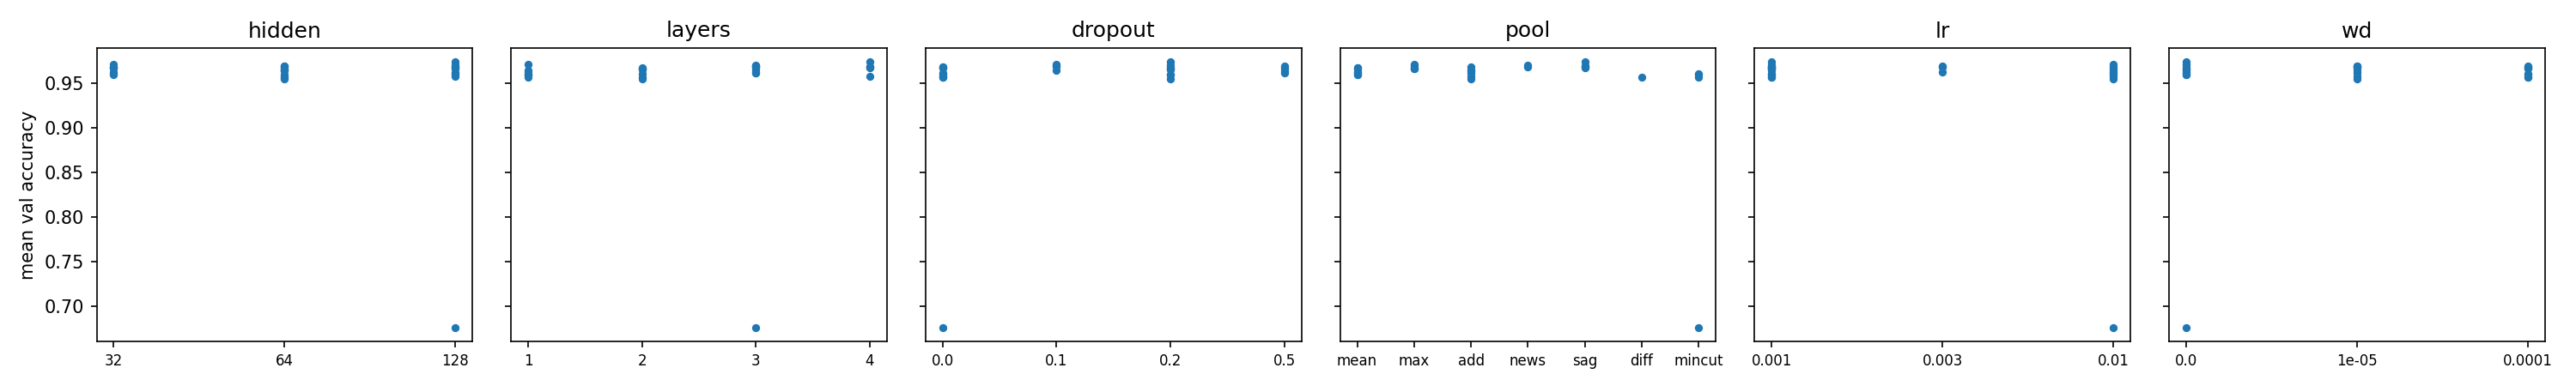

In [14]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = dict(trials[search.index[0]], norm=True, res=True, ffn=True, pe=True)
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(20, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('gcnp_search.png', dpi=150); plt.show()

## 15. Test the tuned GCN⁺ on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the 3,826 test cascades.

In [15]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'plain': base.mean(), 'plain std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

      plain  plain std   tuned  tuned std
acc  0.6151     0.1410  0.9704     0.0022
f1   0.5169     0.2161  0.9704     0.0022
auc  0.9101     0.0353  0.9904     0.0026


## 16. The model we analyse

Analyses that need a single model use the run with the highest validation accuracy among the ten; picking the highest test accuracy would be peeking at the test set. Its confusion matrix shows whether the errors fall mostly on one class.

seed 107   val acc = 0.9762   test: {'acc': 0.9726, 'f1': 0.9726, 'auc': 0.9907}
trainable parameters: 400051


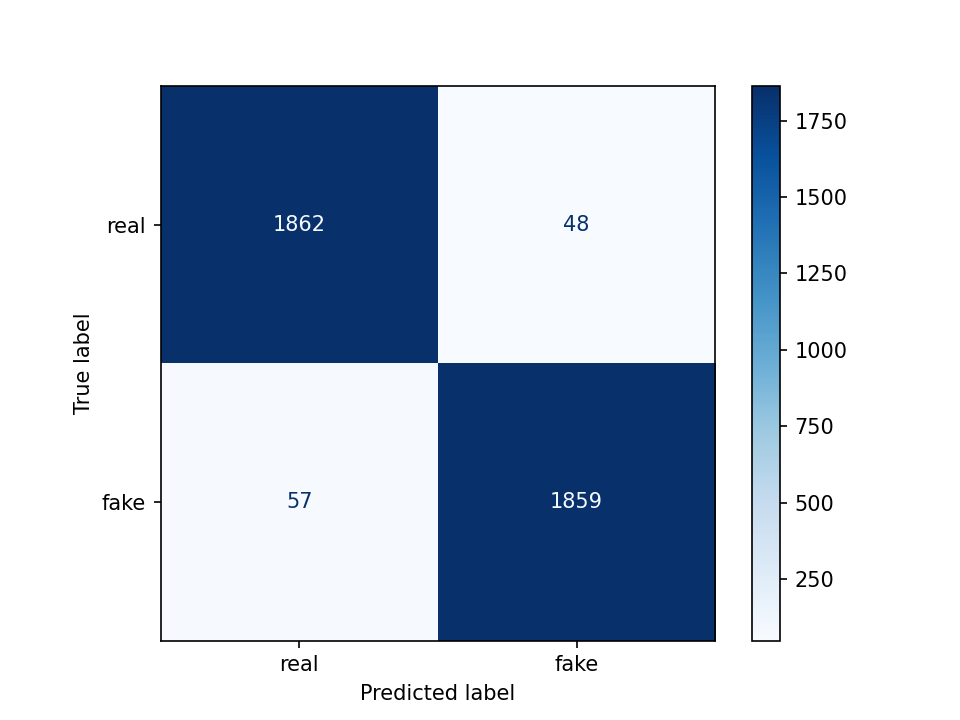

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5), display_labels=['real', 'fake']).plot(cmap='Blues')
plt.savefig('gcnp_confusion.png', dpi=150); plt.show()

## 17. Permutation invariance, checked

A graph has no natural node order, so the prediction must not change when the users are stored in a different order: $\mathrm{READOUT}(\mathbf{P}\mathbf{H})=\mathrm{READOUT}(\mathbf{H})$. We shuffle the users of every test cascade, relabel the edges, and compare the predictions. The news node stays at position 0, because the news-aware readout is told which node is the news item; it is a *different kind* of node, not one whose position we may shuffle. Floating-point sums in a different order give differences of about $10^{-6}$. With SAGPool one more effect can appear: the top-k cut is a hard threshold, so when two nodes' scores differ by less than that rounding error, the shuffle can swap which of them is kept and the probability moves by more than $10^{-6}$. That is a property of hard top-k selection, not a bug; a bug would flip many predictions.

In [17]:
def shuffle_users(g, seed):
    gen = torch.Generator().manual_seed(seed)
    perm = torch.cat([torch.zeros(1, dtype=torch.long), 1 + torch.randperm(g.num_nodes - 1, generator=gen)])
    inv = torch.empty_like(perm); inv[perm] = torch.arange(g.num_nodes)
    h = g.clone()
    h.x, h.pe, h.edge_index = g.x[perm], g.pe[perm], inv[g.edge_index]
    return h

p_shuf = predict(model, batches([shuffle_users(g, i) for i, g in enumerate(test_set)]))
print("largest change in P(fake) after shuffling:", float(np.abs(p_shuf - p_best).max()))
print("predictions that flip:", int(((p_shuf > .5) != (p_best > .5)).sum()), "of", len(p_best))

largest change in P(fake) after shuffling: 1.7881393432617188e-07
predictions that flip: 0 of 3826


## 18. Ablation: which tricks matter on UPFD?

This mirrors the ablation tables of Luo et al. We keep the tuned hyperparameters, switch off **one** trick at a time, and retrain on `abl_seeds`: no normalization, no dropout, no residual connections, no FFN, no positional encoding, and finally all tricks off (the plain GCN with the tuned width, depth and readout). `Δ acc` is the change against the full GCN⁺ on the same seeds.

                           acc      f1     auc  acc std   Δ acc
full GCN⁺               0.9703  0.9703  0.9897   0.0014  0.0000
no normalization        0.9690  0.9690  0.9884   0.0068 -0.0013
no dropout              0.9620  0.9620  0.9872   0.0039 -0.0083
no residual             0.9644  0.9644  0.9877   0.0032 -0.0059
no FFN                  0.9602  0.9602  0.9871   0.0102 -0.0100
no positional encoding  0.9733  0.9733  0.9925   0.0045  0.0031
all tricks off          0.7796  0.7128  0.9201   0.2546 -0.1906


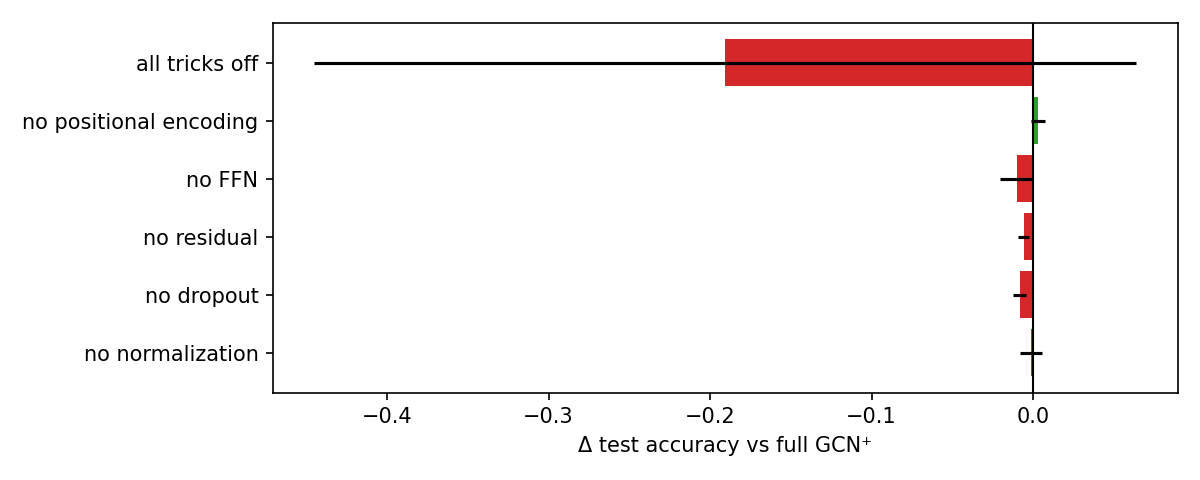

In [18]:
def run(c, seeds=abl_seeds, tr=None, va=None, te=None):
    te = te or test_b
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

def bars(t, ref, fname):
    d = t.iloc[1:]
    plt.figure(figsize=(8, 0.5 + 0.45 * len(d)))
    plt.barh(d.index, d['Δ acc'], xerr=d['acc std'], color=['tab:red' if v < 0 else 'tab:green' for v in d['Δ acc']])
    plt.axvline(0, color='k', lw=1); plt.xlabel(f"Δ test accuracy vs {ref}")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

abl = {'full GCN⁺': tuned.iloc[:len(abl_seeds)]}
for name, change in [('no normalization', dict(norm=False)), ('no dropout', dict(dropout=0.0)),
                     ('no residual', dict(res=False)), ('no FFN', dict(ffn=False)),
                     ('no positional encoding', dict(pe=False)),
                     ('all tricks off', dict(norm=False, res=False, ffn=False, pe=False))]:
    if name == 'no dropout' and best['dropout'] == 0:
        continue
    abl[name] = run(dict(best, **change))
abl_t = table(abl)
print(abl_t)
bars(abl_t, 'full GCN⁺', 'gcnp_ablation.png')

## 19. Ablation: does the model need the edges, the features, the users?

Now the architecture stays tuned and we damage the **input**, in train, validation and test alike (Milestone 3 brief, *Ablation studies*):

- **No edges** ($\mathbf{A}=\mathbf{I}$): each node sees only itself, so message passing becomes a per-node MLP. If accuracy holds, the graph structure is not being used.
- **Constant features**: every $\mathbf{x}_v$ becomes a vector of ones, so only the shape of the cascade is left.
- **News node only**: every user is deleted. This asks whether the cascade adds anything to the article itself.

The positional encodings are recomputed on the damaged graphs, so they cannot leak the structure back in.

In [19]:
def no_edges(g):
    h = g.clone(); h.edge_index = g.edge_index[:, :0]; h.pe = torch.zeros_like(g.pe); return h
def const_x(g):
    h = g.clone(); h.x = torch.ones_like(g.x); return h
def news_only(g):
    h = g.clone(); h.x, h.pe, h.edge_index = g.x[:1], torch.zeros(1, PE_DIM), g.edge_index[:, :0]; return h

inp = {'tuned': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', const_x), ('news node only', news_only)]:
    tr, va, te = [[f(g) for g in d] for d in [train_set, val_set, test_set]]
    inp[name] = run(best, tr=tr, va=batches(va), te=batches(te))
inp_t = table(inp)
print(inp_t)

                      acc      f1     auc  acc std   Δ acc
tuned              0.9703  0.9703  0.9897   0.0014  0.0000
no edges (A = I)   0.9777  0.9777  0.9936   0.0014  0.0075
constant features  0.8209  0.8208  0.8988   0.0034 -0.1493
news node only     0.9587  0.9587  0.9845   0.0018 -0.0116


## 20. Which readout suits UPFD?

Now only the readout changes and everything else stays tuned; `Δ acc` is measured against the tuned readout. The lecture's argument for hierarchical pooling is that one-shot sum, mean or max *forgets how nodes are organised*. A cascade, however, is a shallow star: most users hang directly off the news node, so there are few communities for DiffPool or MinCutPool to find. The news-aware readout tests the opposite idea, that what matters is to keep the article and the users apart.

           acc      f1     auc  acc std   Δ acc
sag     0.9703  0.9703  0.9897   0.0014  0.0000
mean    0.9684  0.9684  0.9904   0.0016 -0.0018
max     0.9732  0.9732  0.9916   0.0030  0.0030
add     0.9623  0.9623  0.9867   0.0037 -0.0080
news    0.9717  0.9717  0.9908   0.0024  0.0015
diff    0.9612  0.9612  0.9838   0.0038 -0.0090
mincut  0.9605  0.9605  0.9852   0.0034 -0.0098


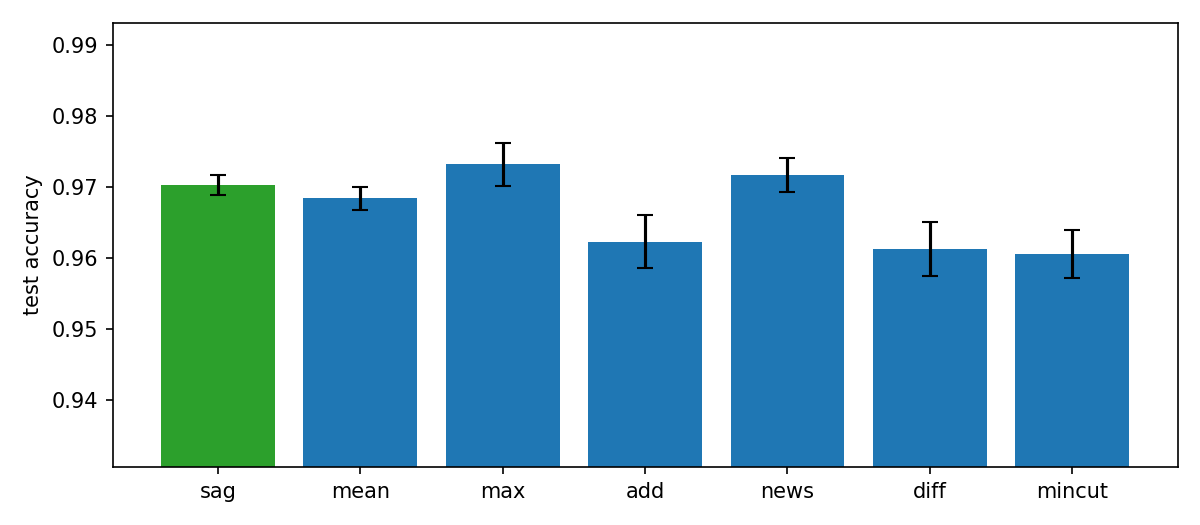

In [20]:
pool_res = {}
for p in [best['pool']] + [q for q in space['pool'] if q != best['pool']]:
    pool_res[p] = tuned.iloc[:len(abl_seeds)] if p == best['pool'] else run(dict(best, pool=p))
pool_t = table(pool_res)
print(pool_t)
plt.figure(figsize=(8, 3.5))
plt.bar(pool_t.index, pool_t.acc, yerr=pool_t['acc std'], capsize=4,
        color=['tab:green' if p == best['pool'] else 'tab:blue' for p in pool_t.index])
plt.ylim(pool_t.acc.min() - 0.03, min(1, pool_t.acc.max() + 0.02)); plt.ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gcnp_readout.png', dpi=150); plt.show()

## 21. Depth with and without residual connections

Lecture 17, *Finding 3*: deep stacks without residuals collapse through over-smoothing, because repeated neighbourhood aggregation pulls every node of a graph towards the same embedding. A cascade is very shallow, so the whole graph is reached within a few hops and over-smoothing should set in early. We train 2, 4, 8 and 16 layers with and without residuals on `sweep_seeds`.

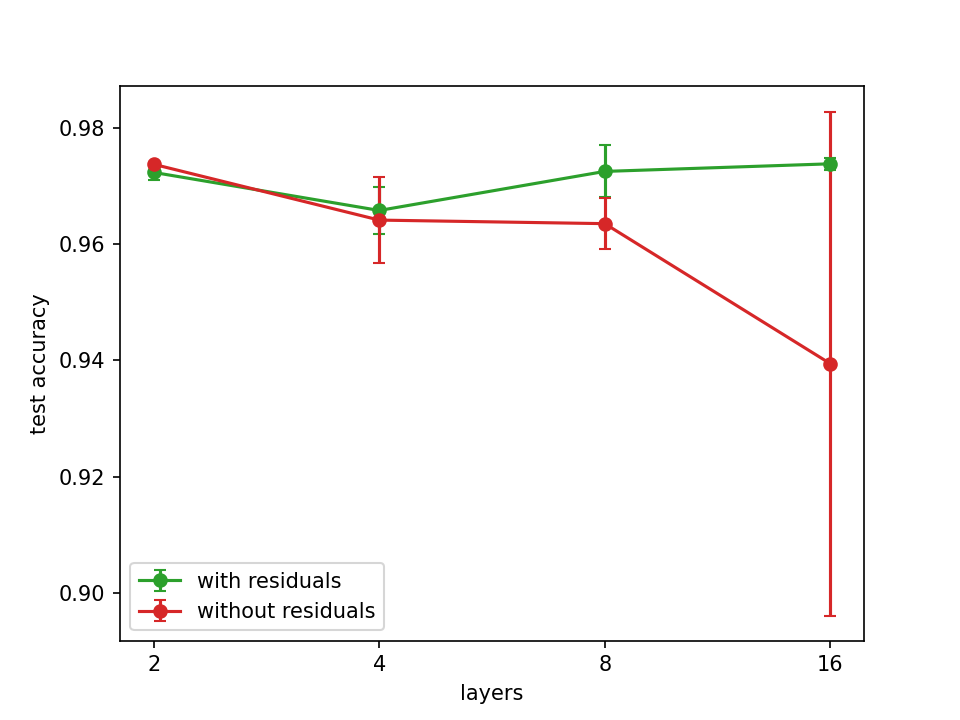

In [21]:
Ls = [2, 4, 8, 16]
depth = {(r, L): run(dict(best, res=r, layers=L), sweep_seeds) for r in [True, False] for L in Ls}
for r, col in [(True, 'tab:green'), (False, 'tab:red')]:
    plt.errorbar(Ls, [depth[r, L].acc.mean() for L in Ls], [depth[r, L].acc.std() for L in Ls],
                 marker='o', capsize=3, color=col, label='with residuals' if r else 'without residuals')
plt.xscale('log', base=2); plt.xticks(Ls, Ls); plt.xlabel("layers"); plt.ylabel("test accuracy"); plt.legend()
plt.savefig('gcnp_depth.png', dpi=150); plt.show()

## 22. Dropout sensitivity

Lecture 17, *Finding 4*: dropout inside message passing distorts every aggregated message, and on the benchmarks of Luo et al. the best rates were mostly 0.2 or lower. We sweep the rate on `sweep_seeds` with everything else tuned.

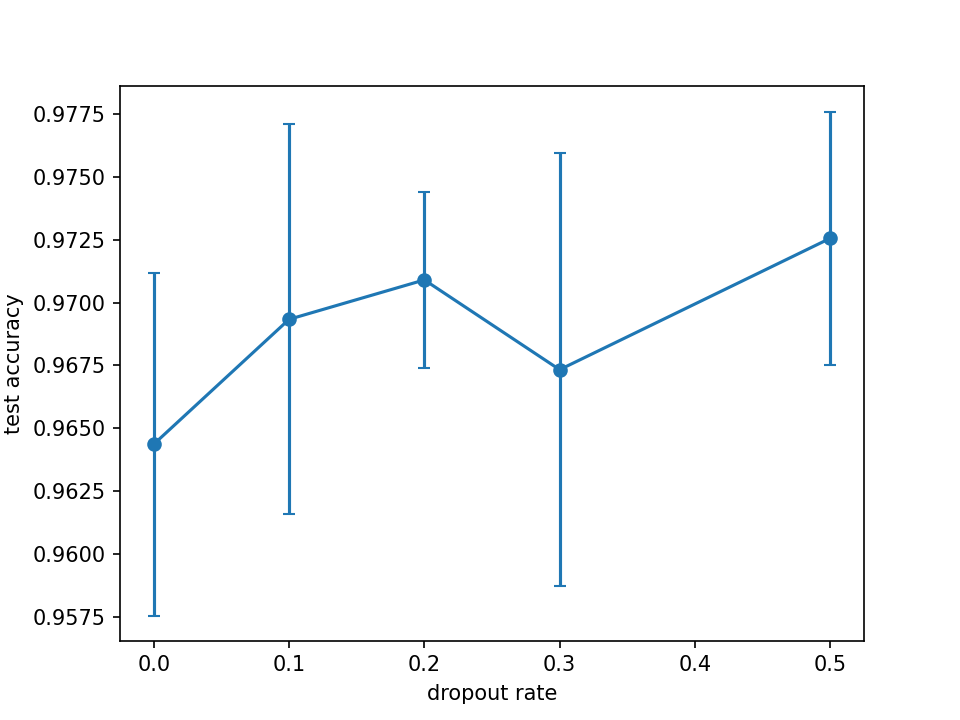

In [22]:
rates = [0.0, 0.1, 0.2, 0.3, 0.5]
drop = {p: run(dict(best, dropout=p), sweep_seeds) for p in rates}
plt.errorbar(rates, [drop[p].acc.mean() for p in rates], [drop[p].acc.std() for p in rates], marker='o', capsize=3)
plt.xlabel("dropout rate"); plt.ylabel("test accuracy")
plt.savefig('gcnp_dropout.png', dpi=150); plt.show()

## 23. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per cascade. t-SNE maps these vectors to 2D while keeping near neighbours near. On the left is the mean of each cascade's raw node features, on the right the tuned GCN⁺ embedding. Colour is the true class, and crosses are cascades the model gets wrong: if they sit on the border between the two clouds, the model fails on genuinely ambiguous cases. The silhouette score, computed in the original space, measures class separation from $-1$ to $1$.

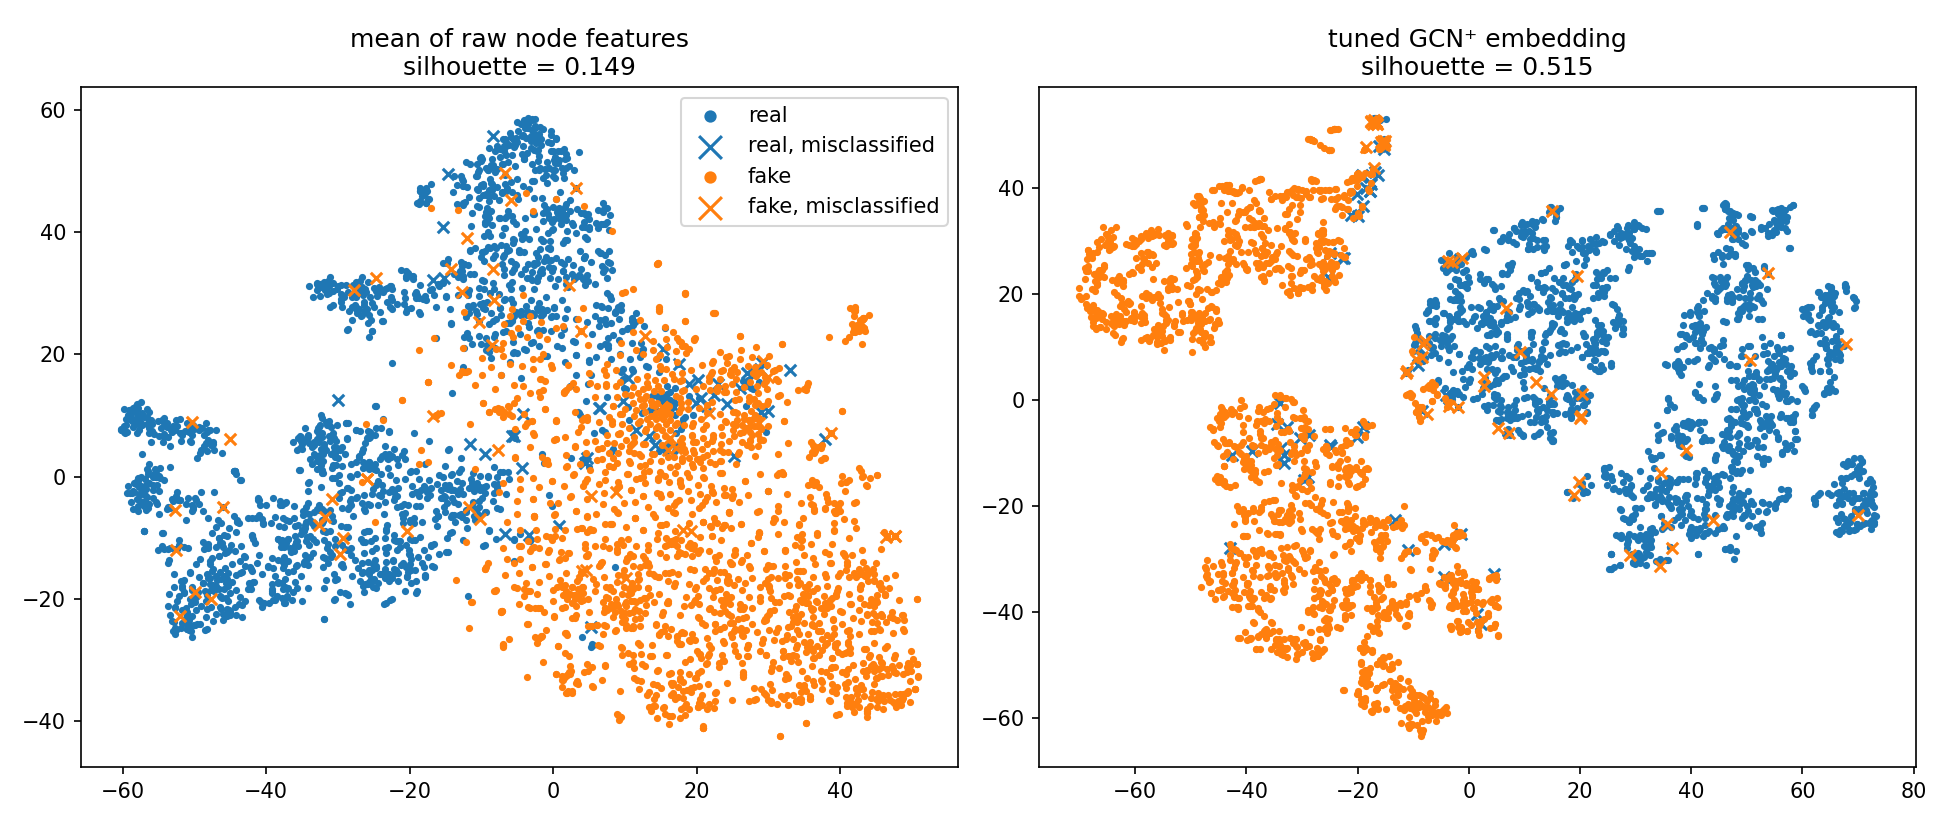

In [23]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.pe, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw node features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GCN⁺ embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col, lab in [(0, 'tab:blue', 'real'), (1, 'tab:orange', 'fake')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=6, c=col, label=lab)
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'{lab}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('gcnp_tsne.png', dpi=150); plt.show()

## 24. Efficiency: what does each readout cost?

Milestone 3 asks for the computational cost of accuracy. For the tuned model and for each readout we measure the number of trainable parameters, the training time per epoch, the time to predict all 3,826 test cascades, and the peak GPU memory during one epoch. Dense DiffPool and MinCutPool build an $n_{\max}\times n_{\max}$ adjacency for every graph in the batch, so they should be the most expensive. Each number is the median of three epochs after one warm-up epoch.

In [24]:
def cost(c):
    seed_everything(0)
    m = Net(**c).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=c['lr'])
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    times = []
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    for e in range(4):
        if device == 'cuda': torch.cuda.synchronize()
        t = time.time(); m.train()
        for b in loader:
            b = b.to(device); opt.zero_grad()
            (F.cross_entropy(m(b.x, b.edge_index, b.pe, b.batch), b.y) + m.aux).backward(); opt.step()
        if device == 'cuda': torch.cuda.synchronize()
        times.append(time.time() - t)
    t = time.time(); predict(m, test_b)
    if device == 'cuda': torch.cuda.synchronize()
    return dict(params=sum(p.numel() for p in m.parameters()), s_per_epoch=float(np.median(times[1:])),
                infer_s=time.time() - t, peak_mb=torch.cuda.max_memory_allocated() / 2**20 if device == 'cuda' else float('nan'))

eff = pd.DataFrame({p: cost(dict(best, pool=p)) for p in space['pool']}).T
eff['test acc'] = pool_t.acc.reindex(eff.index)
print(eff.round(4))

          params  s_per_epoch  infer_s   peak_mb  test acc
mean    383538.0       0.2899   0.1460  479.7383    0.9684
max     383538.0       0.2810   0.1466  482.6733    0.9732
add     383538.0       0.2941   0.1454  479.7383    0.9623
news    416306.0       0.3149   0.1526  482.4199    0.9717
sag     400051.0       0.3354   0.1670  482.0962    0.9703
diff    401985.0       0.3722   0.2027  555.2554    0.9612
mincut  418369.0       0.3982   0.2064  520.1348    0.9605


## 25. Robustness: missing edges and noisy features

A deployed detector sees incomplete cascades (deleted retweets, private accounts) and noisy profiles. Without retraining, we damage only the **test** cascades and measure how fast accuracy falls (Milestone 3 brief, *Robustness*):

- **Edge removal**: drop a fraction of the retweet edges, both directions together, at random; positional encodings are recomputed on the damaged graph.
- **Feature noise**: add Gaussian noise $\mathcal{N}(0,\sigma^2)$ to every node feature. The features lie roughly in $[-1,1]$, so $\sigma=0.5$ is heavy noise.

Each point is the mean over three random damages.

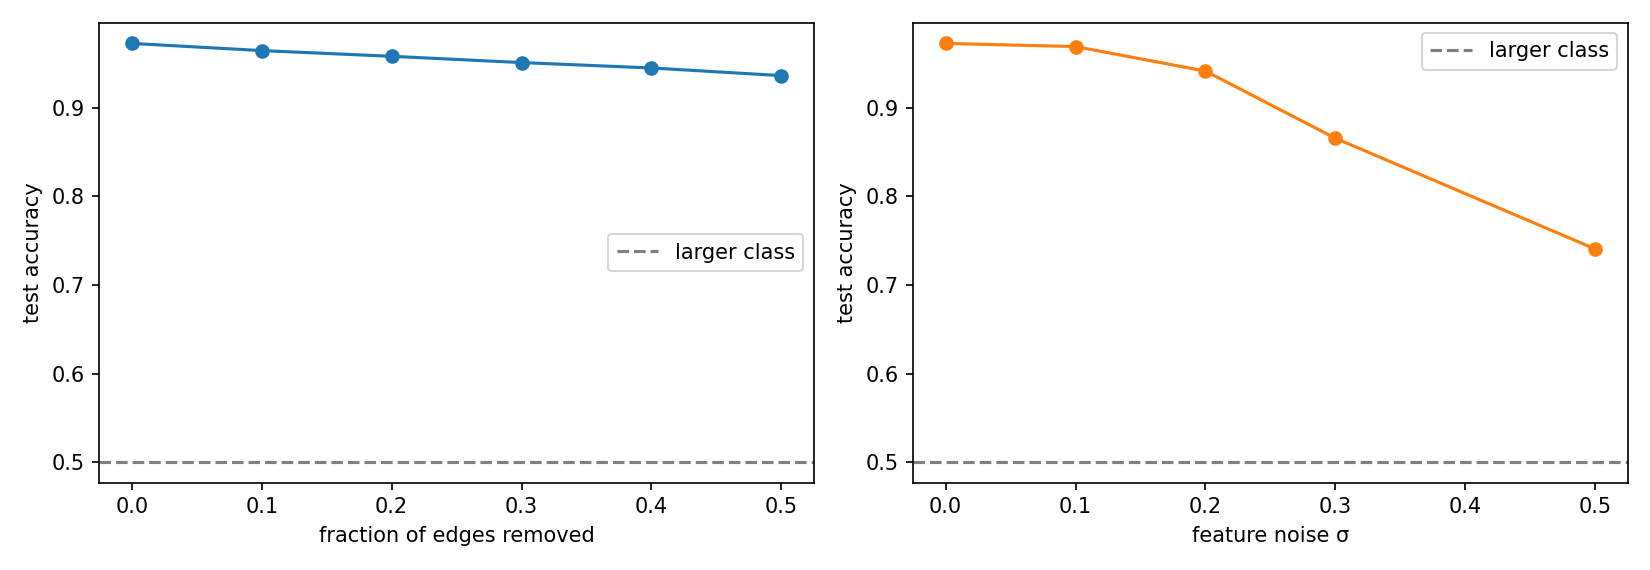

In [25]:
from torch_geometric.utils import dropout_edge

def drop_edges(g, p, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.edge_index, _ = dropout_edge(g.edge_index, p=p, force_undirected=True)
    h.pe = rw(h).pe[:, 1::2]; return h
def noisy(g, s, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.x = g.x + s * torch.randn_like(g.x); return h

edge_ps, sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5], [0.0, 0.1, 0.2, 0.3, 0.5]
rob_edge = {p: np.mean([accuracy_score(y_test, predict(model, batches([drop_edges(g, p, r) for g in test_set])) > .5) for r in range(3)]) for p in edge_ps}
rob_noise = {s: np.mean([accuracy_score(y_test, predict(model, batches([noisy(g, s, r) for g in test_set])) > .5) for r in range(3)]) for s in sigmas}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(edge_ps, list(rob_edge.values()), marker='o'); ax[0].set_xlabel("fraction of edges removed")
ax[1].plot(sigmas, list(rob_noise.values()), marker='o', color='tab:orange'); ax[1].set_xlabel("feature noise σ")
for a in ax:
    a.axhline(majority, ls='--', c='grey', label='larger class'); a.set_ylabel("test accuracy"); a.legend()
plt.tight_layout(); plt.savefig('gcnp_robustness.png', dpi=150); plt.show()

## 26. Error analysis by cascade shape

The brief's examples are node-level (accuracy by node degree); for graph classification the natural unit is the cascade. We describe every test cascade by three structural properties and group the test accuracy by quartile of each:

- **size** $|V|$, the number of users who shared the story;
- **depth**, the longest retweet chain from the news node;
- **star-ness**, the fraction of users who retweeted the news node directly rather than another user.

A model that leans on the structure should be most accurate on cascades whose shape is typical of their class.


size
                  acc    n   fake
size                            
(2.999, 19.0]  0.955  982  0.894
(19.0, 49.0]   0.981  940  0.583
(49.0, 83.0]   0.981  951  0.242
(83.0, 199.0]  0.974  953  0.273

depth
                 acc     n   fake
depth                           
(1.999, 3.0]  0.973  3348  0.493
(3.0, 9.0]    0.969   478  0.559

star
                    acc    n   fake
star                              
(0.0293, 0.667]  0.946  964  0.666
(0.667, 0.849]   0.979  949  0.623
(0.849, 0.946]   0.980  956  0.563
(0.946, 0.993]   0.985  957  0.152


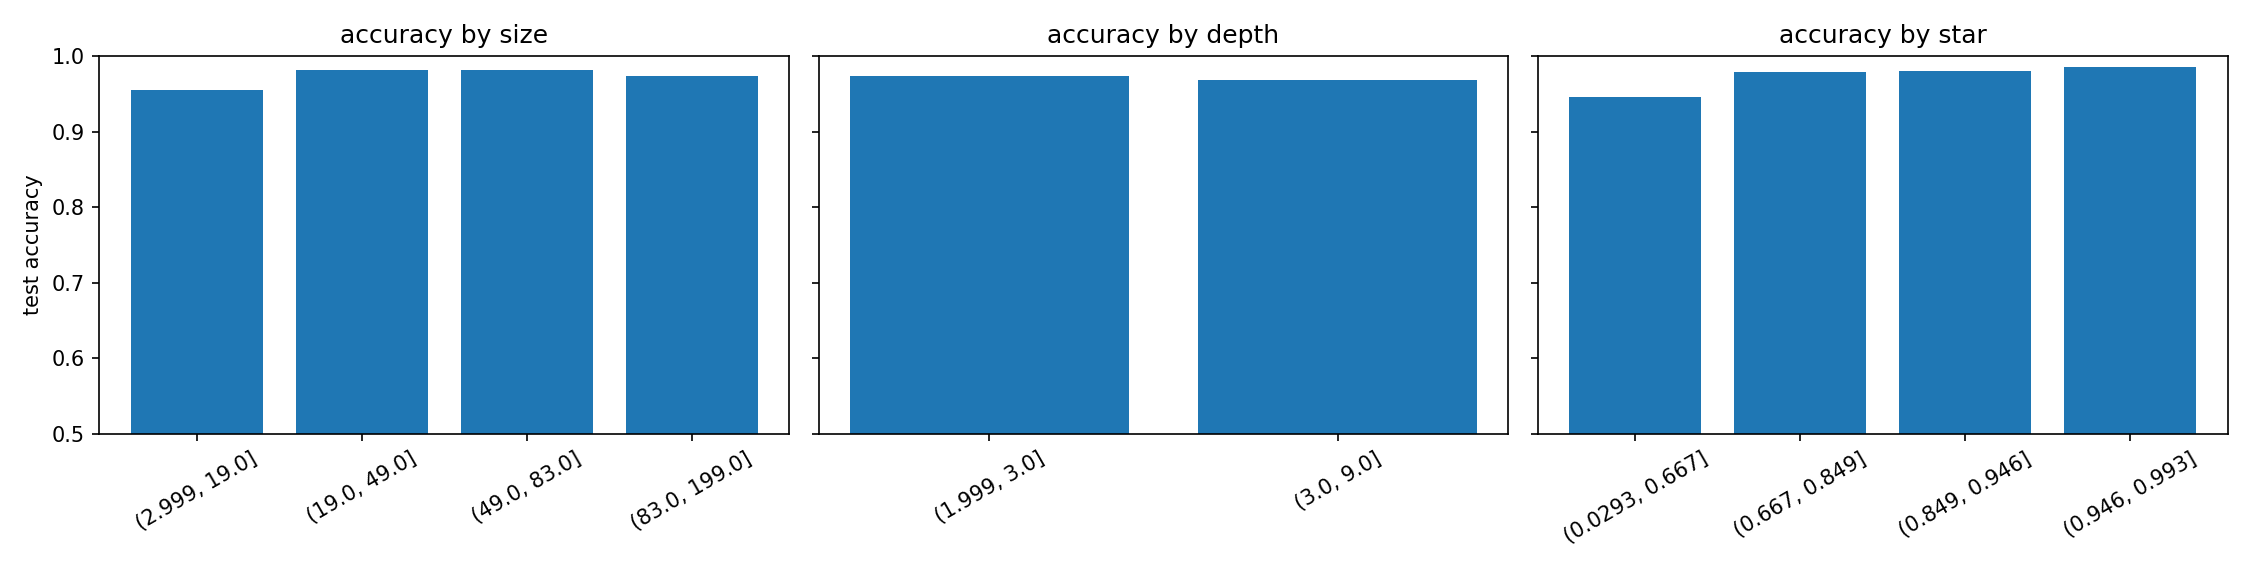

In [26]:
from torch_geometric.utils import to_scipy_sparse_matrix
from scipy.sparse.csgraph import shortest_path

def shape(g):
    d = shortest_path(to_scipy_sparse_matrix(g.edge_index, num_nodes=g.num_nodes), indices=0, unweighted=True)
    return dict(size=g.num_nodes, depth=int(d[np.isfinite(d)].max()), star=float((d == 1).sum() / max(1, g.num_nodes - 1)))

shp = pd.DataFrame([shape(g) for g in test_set])
shp['correct'] = (p_best > .5) == y_test
shp['fake'] = y_test
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
topo = {}
for a, col in zip(ax, ['size', 'depth', 'star']):
    q = pd.qcut(shp[col], 4, duplicates='drop')
    t = shp.groupby(q, observed=True).agg(acc=('correct', 'mean'), n=('correct', 'size'), fake=('fake', 'mean'))
    topo[col] = t.reset_index().astype(str).to_dict('records')
    print(f"\n{col}\n", t.round(3))
    a.bar([str(i) for i in t.index], t.acc, color='tab:blue'); a.set_title(f"accuracy by {col}")
    a.tick_params(axis='x', rotation=30); a.set_ylim(0.5, 1)
ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gcnp_topology.png', dpi=150); plt.show()

## 27. Explainability: which users drive the prediction?

We ask **GNNExplainer** (Ying et al., NeurIPS 2019) which nodes of a cascade the tuned model relies on. For one graph it learns a soft mask over the nodes that keeps the prediction while using as few nodes as possible, and returns an importance score per node.

A mask is only useful if it is faithful. We measure **fidelity** by deletion: remove the top 10% most important users (the news node always stays) and record how much the predicted probability of the predicted class drops. If the explainer is right, this drop should be much larger than when we remove the same number of *random* users. We do this on 100 test cascades with at least 20 nodes.

GNNExplainer writes its mask into the message-passing layers of the model it explains, which corrupts that model for later use, so we explain a copy.

In [27]:
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import subgraph

expl = Explainer(model=copy.deepcopy(model), algorithm=GNNExplainer(epochs=100),
                 explanation_type='model', node_mask_type='object', edge_mask_type=None,
                 model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw'))

@torch.no_grad()
def prob(g):
    model.eval(); g = g.clone().to(device)  # Data.to() moves in place; keep the caller's graph on the CPU
    return model(g.x, g.edge_index, g.pe, g.edge_index.new_zeros(g.num_nodes)).softmax(1)[0].cpu()

def delete(g, drop):
    keep = torch.ones(g.num_nodes, dtype=torch.bool); keep[drop] = False; keep[0] = True
    ei, _ = subgraph(keep, g.edge_index, relabel_nodes=True, num_nodes=g.num_nodes)
    h = g.clone(); h.x, h.edge_index = g.x[keep], ei; h.pe = rw(h).pe[:, 1::2]; return h

rng = np.random.default_rng(0)
cand = [i for i, g in enumerate(test_set) if g.num_nodes >= 20]
picked = rng.choice(cand, size=min(100, len(cand)), replace=False)
fid, masks = [], {}
for i in picked:
    g = test_set[i].clone().to(device)
    m_ = expl(g.x, g.edge_index, pe=g.pe, batch=g.edge_index.new_zeros(g.num_nodes)).node_mask.flatten().cpu()
    masks[int(i)] = m_
    g = g.cpu(); p0 = prob(g); c = int(p0.argmax()); kk = max(1, int(0.1 * (g.num_nodes - 1)))
    order = 1 + torch.argsort(m_[1:], descending=True)
    rand = 1 + torch.from_numpy(rng.permutation(g.num_nodes - 1))
    fid.append(dict(top=float(p0[c] - prob(delete(g, order[:kk]))[c]), random=float(p0[c] - prob(delete(g, rand[:kk]))[c]),
                    news_rank=int((m_ > m_[0]).sum())))
fid = pd.DataFrame(fid)
print("mean drop in confidence, top-10% users removed:   ", round(fid.top.mean(), 4))
print("mean drop in confidence, random 10% users removed:", round(fid.random.mean(), 4))
print("news node ranked in the top 3 most important nodes:", round((fid.news_rank < 3).mean(), 3))

mean drop in confidence, top-10% users removed:    0.0009
mean drop in confidence, random 10% users removed: 0.0083
news node ranked in the top 3 most important nodes: 0.04


## 28. Explained cascades

We draw three explained cascades, one correctly classified fake, one correctly classified real, and one error, with node colour showing GNNExplainer's importance and the news node drawn as a square. A useful explanation would point at a group of users, for instance a burst of early retweeters, rather than spread its importance evenly.

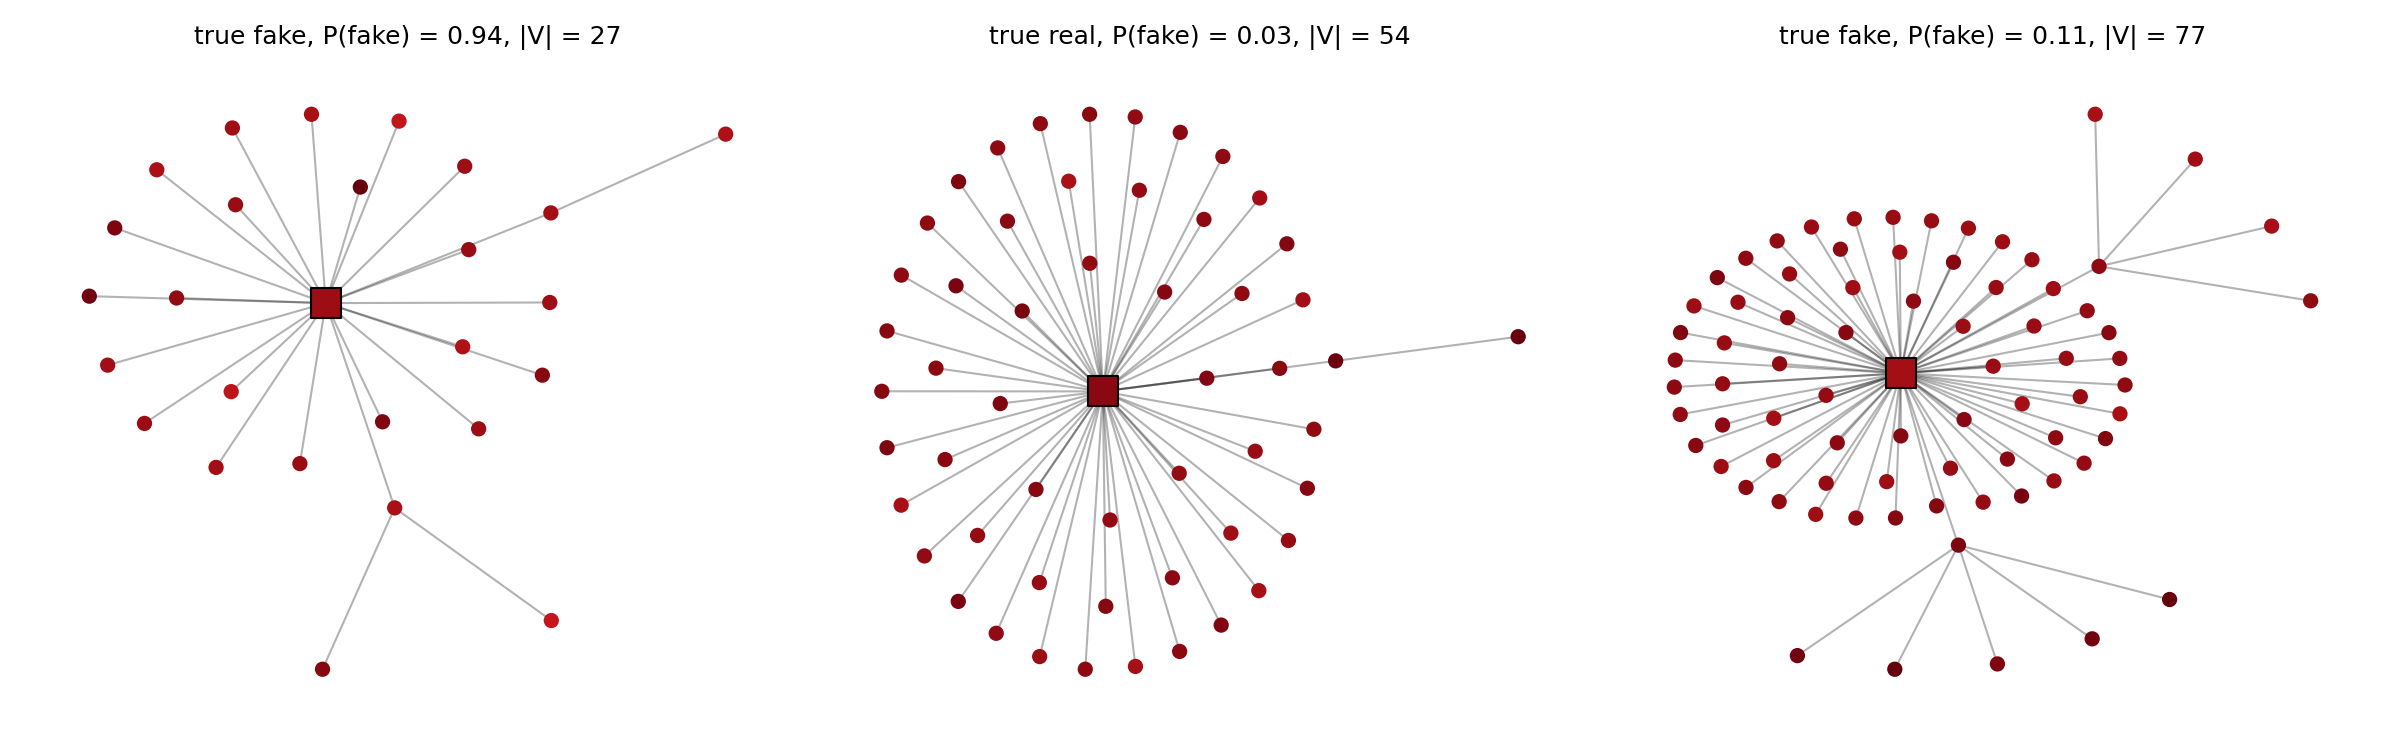

In [28]:
import networkx as nx
from torch_geometric.utils import to_networkx

def pick(cond):
    for i in masks:
        if cond(i): return i
chosen = [pick(lambda i: y_test[i] == 1 and p_best[i] > .5), pick(lambda i: y_test[i] == 0 and p_best[i] <= .5),
          pick(lambda i: (p_best[i] > .5) != y_test[i])]
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, i in zip(ax, chosen):
    if i is None: a.axis('off'); continue
    G = to_networkx(test_set[i], to_undirected=True); pos = nx.kamada_kawai_layout(G); w = masks[i].numpy()
    nx.draw_networkx_edges(G, pos, ax=a, alpha=.3)
    nx.draw_networkx_nodes(G, pos, nodelist=list(range(1, len(w))), node_color=w[1:], cmap='Reds', vmin=0, vmax=w.max(), node_size=40, ax=a)
    nx.draw_networkx_nodes(G, pos, nodelist=[0], node_color=[w[0]], cmap='Reds', vmin=0, vmax=w.max(), node_shape='s', node_size=200, edgecolors='k', ax=a)
    a.set_title(f"true {'fake' if y_test[i] else 'real'}, P(fake) = {p_best[i]:.2f}, |V| = {len(w)}"); a.axis('off')
plt.tight_layout(); plt.savefig('gcnp_explained_cascades.png', dpi=150); plt.show()

## 29. Explainability: which feature block matters?

Each node's 310 features have two parts: 300 dimensions of text (spaCy embedding of the article or the user's tweets) and 10 profile features (followers, account age, and so on). We measure the drop in confidence when one block is replaced by its training-set mean, for the news node and for the users separately (the brief's *drop in confidence when features are masked*).

In [29]:
mu = torch.cat([g.x for g in train_set]).mean(0)
def mask_block(g, cols, who):
    h = g.clone(); rows = slice(0, 1) if who == 'news' else slice(1, None)
    h.x[rows, cols] = mu[cols]; return h

p_c = np.where(p_best > .5, p_best, 1 - p_best)
feat = {}
for who in ['news', 'users']:
    for blk_name, cols in [('text (300)', slice(0, 300)), ('profile (10)', slice(300, 310))]:
        p = predict(model, batches([mask_block(g, cols, who) for g in test_set]))
        feat[f'{who}: {blk_name}'] = dict(conf_drop=float(np.mean(p_c - np.where(p_best > .5, p, 1 - p))),
                                          acc=accuracy_score(y_test, p > .5))
feat = pd.DataFrame(feat).T
print(feat.round(4))

                     conf_drop     acc
news: text (300)        0.0082  0.9728
news: profile (10)      0.0011  0.9733
users: text (300)       0.4388  0.5005
users: profile (10)     0.0359  0.9631


## 30. Save the results

Everything needed to compare this model with the others goes into one JSON file. The per-run test probabilities are saved too, so the errors of all models can later be compared graph by graph.

In [30]:
import json
res = dict(model='GCN⁺', dataset='UPFD gossipcop', references=dict(majority=majority, size_only=size_acc, news_only=news_acc),
           best_config=best, plain=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(),
           tuned_runs=tuned.to_dict('list'), params=sum(p.numel() for p in model.parameters()),
           permutation_max_change=float(np.abs(p_shuf - p_best).max()),
           ablation=abl_t.to_dict('index'), input_ablation=inp_t.to_dict('index'), readout=pool_t.to_dict('index'),
           depth={f'res={r}, layers={L}': [v.acc.mean(), v.acc.std()] for (r, L), v in depth.items()},
           dropout={str(p): [v.acc.mean(), v.acc.std()] for p, v in drop.items()},
           silhouette=sil, efficiency=eff.to_dict('index'),
           robustness=dict(edges={str(k): v for k, v in rob_edge.items()}, noise={str(k): v for k, v in rob_noise.items()}),
           topology=topo, fidelity=fid.mean().to_dict(), feature_masking=feat.to_dict('index'),
           minutes=(time.time() - t0) / 60)
json.dump(res, open('gcnp_upfd_results.json', 'w'), indent=1, default=float)
np.save('gcnp_upfd_test_probs.npy', P)
search.to_csv('gcnp_upfd_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, best_config, dataset, depth, dropout, efficiency, feature_masking, fidelity, input_ablation, minutes, model, params, permutation_max_change, plain, readout, references, robustness, silhouette, topology, tuned, tuned_runs
total run time: 84 minutes


## 31. Conclusion

*To be written from the Kaggle run.*